Prepared Dataset:
   YearsExperience  Salary
0              1.1   39343
1              1.3   46205
2              1.5   37731
3              2.0   43525
4              2.2   39891

Training data: 20
Testing data: 5

Model Training Completed!

Predictions:
   Actual Salary  Predicted Salary
0          57189          60894.16
1          93940          83230.81
2          39343          35644.03
3         116969         117221.36
4          61111          68663.43

Model Evaluation:
Mean Absolute Error: 5183.6204967077965
Mean Squared Error: 39840042.975979544
R2 Score: 0.9488359499426934

Coefficient: 9711.586156469106
Intercept: 24961.289224966444

Predicted salary for 6.5 years experience: 88086.6


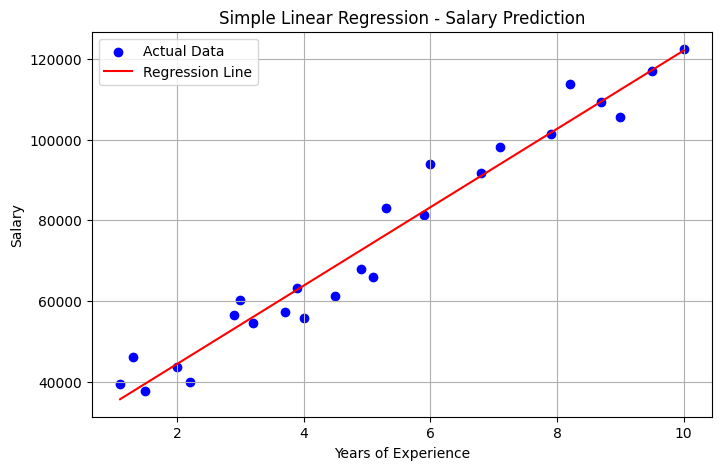

In [1]:

# DAY 33 - SIMPLE LINEAR REGRESSION

# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 2. Prepare the dataset
data = {
    'YearsExperience': [1.1, 1.3, 1.5, 2.0, 2.2,
                        2.9, 3.0, 3.2, 3.7, 3.9,
                        4.0, 4.5, 4.9, 5.1, 5.3,
                        5.9, 6.0, 6.8, 7.1, 7.9,
                        8.2, 8.7, 9.0, 9.5, 10.0],
    'Salary': [39343, 46205, 37731, 43525, 39891,
               56642, 60150, 54445, 57189, 63218,
               55794, 61111, 67938, 66029, 83088,
               81363, 93940, 91738, 98273, 101302,
               113812, 109431, 105582, 116969, 122391]
}

df = pd.DataFrame(data)

print("Prepared Dataset:")
print(df.head())

# 3. Save prepared dataset
df.to_csv("salary_dataset.csv", index=False)

# 4. Select feature and target
X = df[['YearsExperience']]
y = df['Salary']

# 5. Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nTraining data:", len(X_train))
print("Testing data:", len(X_test))

# 6. Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

print("\nModel Training Completed!")

# 7. Predict test data
y_pred = model.predict(X_test)

results = pd.DataFrame({
    'Actual Salary': y_test.values,
    'Predicted Salary': y_pred.round(2)
})

print("\nPredictions:")
print(results)

# 8. Evaluate the model
print("\nModel Evaluation:")
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

print("\nCoefficient:", model.coef_[0])
print("Intercept:", model.intercept_)

# 9. Predict salary for new experience
new_experience = pd.DataFrame({'YearsExperience': [6.5]})
predicted_salary = model.predict(new_experience)

print("\nPredicted salary for 6.5 years experience:",
      round(predicted_salary[0], 2))

# 10. Visualize regression line
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='blue', label='Actual Data')
plt.plot(X, model.predict(X), color='red',
         label='Regression Line')

plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.title("Simple Linear Regression - Salary Prediction")
plt.legend()
plt.grid(True)
plt.show()
